# Stage 3 tests: two-lane main road with a metered one-lane on-ramp

**CEE C181/C281, Fall 2026 · Colin & Pratiyush**

This notebook tests the Stage 3 simulator against the equations and parameter values in our Intermediate 1 proposal and the lecture slides.

**How it uses the HTML model.** The simulator is the JavaScript inside `two_lane_merge.html`. `simtools/sim_runner.js` loads that file, removes the drawing code, seeds the random numbers, and runs the same physics in Node.js. `simtools.run_stage3()` calls it from Python, so every test here runs the real model, not a copy. If you edit the HTML, rerun this notebook to retest it.

**Requirements:** Python 3.10+, `pip install -r requirements.txt`, and Node.js 18+ (`node --version`; on a Mac, `brew install node`).

**How to read the results.** Each test ends with one line:
- **PASS:** the model matches the expected value within the stated tolerance.
- **FLAG:** the model disagrees with the expected value or the proposal. This needs a decision or a fix.
- **INFO:** a measurement with no pass/fail rule, reported for the midterm write-up.

Units: the HTML works in feet, mph and veh/h. This notebook reports SI (m, s, km/h) alongside the code units where it helps.

In [1]:
import sys, time, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

REPO = Path.cwd().resolve()
while not (REPO / "simtools").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
import simtools as st
from simtools import theory as th

OUT = REPO / "stage3_two_lane_merge" / "results"
OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .3})

FT, MPH, KMH = 0.3048, 0.44704, 1.609344      # m per ft, m/s per mph, km/h per mph
RESULTS = []
def record(test, verdict, detail):
    RESULTS.append(dict(test=test, result=verdict, detail=detail))
    print(f"{verdict}: {test} — {detail}")

T0 = time.time()
print("Model file:", st.STAGE3_HTML.relative_to(REPO))
probe = st.run_stage3(duration_s=60)
print("Node runner OK. Code constants:", {k: probe["consts"][k] for k in ("DT","CL","IA","IB","S0","POL","ATHR")})

Model file: stage3_two_lane_merge/two_lane_merge.html
Node runner OK. Code constants: {'DT': 0.1, 'CL': 15, 'IA': 5, 'IB': 9, 'S0': 8, 'POL': 0.2, 'ATHR': 0.33}


## 1. Model and equations

These are the equations the code implements and the tests check, in the notation of the proposal and Lecture 04.

**Stream variables** (Lecture 03): $q = u_s\,k$. At a point detector the space-mean speed is the harmonic mean of spot speeds, $u_s = n / \sum_i (1/v_i)$, and the time-mean speed $\bar u_t = \frac{1}{n}\sum_i v_i \ge u_s$ (Lecture 02).

**Demand** (proposal 1.1): $q_{peak} = \text{AADT}\cdot K \cdot D$, with $K \approx 0.08$–$0.12$ and $D \approx 0.5$–$0.6$. Arrivals are Poisson with exponential headways $h \sim \text{Exp}(\lambda)$, $\lambda = q/3600$.

**Intelligent Driver Model** (Lecture 04, slides 37–41; Treiber et al., 2000). Each car α has $\dot x_\alpha = v_\alpha$ and
$$\dot v_\alpha = a\left[1 - \left(\frac{v}{v_0}\right)^{\delta} - \left(\frac{s^*(v,\Delta v)}{s}\right)^2\right], \qquad s^*(v,\Delta v) = s_0 + \max\!\left(0,\; vT + \frac{v\,\Delta v}{2\sqrt{ab}}\right)$$
where $s_\alpha = x_l - l_l - x_\alpha$ is the gap to the leader and $\Delta v_\alpha = v_\alpha - v_l$. In the code this is `idm(v, v0, s, dv)`.

**Ballistic update** (Lecture 04, slide 11, Eq. 10.9–10.10), with $\Delta t = 0.1$ s:
$$v(t+\Delta t) = \max\big(0,\; v(t) + \dot v\,\Delta t\big), \qquad x(t+\Delta t) = x(t) + v(t+\Delta t)\,\Delta t$$
(the code adds the new speed times Δt, a semi-implicit variant of the ballistic scheme).

**Equilibrium and capacity** (Lecture 04, Eq. 10.12–10.16). Setting $\dot v = 0$ and $\Delta v = 0$:
$$s_e(v) = \frac{s_0 + vT}{\sqrt{1 - (v/v_0)^{\delta}}}, \qquad k = \frac{1}{s_e + l}, \qquad Q_e(k) = k\,v_e(k), \qquad C_{lane} = \max_k Q_e(k)$$
Capacity depends on $v_0, T, s_0, l, \delta$ but **not** on $a$ or $b$.

**Newell's model** (Lecture 04, slides 24–27): $v(t+T) = \min\!\big(v_0,\; s(t)/T\big)$, with congested wave speed $w = -l_{eff}/T$, observed range $-20$ to $-15$ km/h.

**Lane changing, MOBIL** (Lecture 04, slides 47–49, Eq. 14.4; Kesting et al., 2007). A car changes lanes if
$$\tilde a_c - a_c + p\big[(\tilde a_{\hat f} - a_{\hat f}) + (\tilde a_f - a_f)\big] > \Delta a_{th} \quad\text{and}\quad \tilde a_{\hat f} > -b_{safe}$$
(own gain plus politeness × followers' gain beats a threshold; the new follower $\hat f$ never brakes harder than $b_{safe}$).

**Merge and ramp queue** (Lecture 03; proposal 1.1). With Poisson main-lane traffic, acceptable gaps per hour $= V e^{-\lambda t_c}$. The metered ramp is an M/D/1 queue with $\rho = \lambda/\mu$:
$$L_q = \bar Q = \frac{\rho^2}{2(1-\rho)}, \qquad L = L_q + \rho$$
($L_q$ counts cars waiting; $L$ also counts the car at the stop line.) Behind a crash, a D/D/1 queue grows to $(V - c_R)\,t_{inc}$.

**Shockwaves** (Lecture 03, slides 34–48): $\omega_{AB} = \dfrac{q_A - q_B}{k_A - k_B}$.

**Safety** (Lectures 08A/08B; proposal 1.2): $N = R \cdot \text{AADT} \cdot L \cdot 365 / 10^6$; HSM SPF $N_{pred} = L\,e^{\beta_0}\,\text{AADT}^{\beta_1}\prod \text{CMF}_i$; Power Model $N_2/N_1 = (v_2/v_1)^n$ with $n\approx2$ (injury), $4$ (fatal); conflict when $\text{TTC} = s/\Delta v < 3$ s.

The code implements the stream variables, demand as a slider, IDM, ballistic update, MOBIL, the meter queue and the crash-rate model. HSM SPFs, the Power Model and TTC are not in Stage 3 yet (see the parameter table).

## 2. Parameters: code vs. proposal, with plausible ranges

`simtools/params.py` lists every parameter with its value in the code, the value planned in the proposal, the plausible range the proposal cites (mostly Lecture 04 Table 11.2), and where it lives in the HTML (`slider` = adjustable in the page; `const` = hard-coded). Status rules: within 2% of the proposal value = matches; outside the cited range = OUTSIDE range.

In [2]:
ptab = st.params.table()
show = ptab[["symbol","meaning","unit","code_si","code_as_written","proposal_si","low","high","where","status","source"]]
ptab.to_csv(OUT / "parameters_code_vs_proposal.csv", index=False)
display(show)
print(ptab["status"].value_counts().to_string())
bad = ptab[ptab.status.str.contains("OUTSIDE|DIFFERS")]
record("Parameters vs. proposal", "FLAG" if len(bad) else "PASS",
       f"{len(bad)} differ or fall outside the cited range: " + ", ".join(bad.symbol))

,symbol,meaning,unit,code_si,code_as_written,proposal_si,low,high,where,status,source
0,v0,mean desired speed,m/s,13.411,30 mph (slider 'mean'),NaN,15.646,33.528,slider,OUTSIDE range,Proposal 2.2 grid: speed limit 35/55/75 mph; L...
1,σ_v0,spread of desired speed,m/s,2.235,5 mph (slider 'sd'),2.235,NaN,NaN,slider,matches proposal,Proposal 1.3 (Gaussian σ ≈ 5 mph); Lecture 05B
2,T,desired time gap,s,1.000,1.0 s (slider 'headway'),1.000,1.000,1.600,slider,matches proposal,"Lecture 04 Table 11.2, Fig. 11.2; proposal gri..."
3,s0,standstill gap,m,2.438,8 ft (const S0),2.000,1.000,3.000,const,"differs, inside range",Lecture 04 Table 11.2
4,a,maximum acceleration,m/s²,1.524,5 ft/s² (const IA),1.000,0.730,1.000,const,OUTSIDE range,Lecture 04 Table 11.2; Treiber et al. (2000)
5,b,comfortable deceleration,m/s²,2.743,9 ft/s² (const IB),1.500,1.500,1.670,const,OUTSIDE range,Lecture 04 Table 11.2; Treiber et al. (2000)
6,δ,acceleration exponent,–,4.000,4 (in idm()),4.000,4.000,4.000,const,matches proposal,Lecture 04 Table 11.2
7,l,vehicle length,m,4.572,15 ft (const CL),5.000,NaN,NaN,const,DIFFERS from proposal,Lecture 04 Table 11.2 (car)
8,occ,people per car,persons,1.500,1.5 (slider 'ppc'),1.500,NaN,NaN,slider,matches proposal,"Proposal 1.3, assumed"
9,b_safe,max braking imposed on new follower (MOBIL),m/s²,3.962,13 ft/s² (slider 'bsafe'),4.000,NaN,NaN,slider,matches proposal,Proposal 1.1 and 2.2; Lecture 04 Eq. 14.4


status
matches proposal                      14
OUTSIDE range                          5
code only (proposal sets no value)     5
not in code                            5
DIFFERS from proposal                  2
differs, inside range                  1
FLAG: Parameters vs. proposal — 7 differ or fall outside the cited range: v0, a, b, l, q_A, q_B, μ


## Test 1: the code's `idm()` matches the lecture IDM equation

We send 2,000 random (v, v₀, s, Δv) combinations to the HTML's own `idm()` function and compare with the formula in Section 1, evaluated in Python with the code's constants (a = 5 ft/s², b = 9 ft/s², s₀ = 8 ft, δ = 4, T = 1 s). The code also floors s at 0.5 ft and v₀ at 1 ft/s to avoid dividing by zero, so samples stay above those floors.

In [3]:
rng = np.random.default_rng(0)
n = 2000
v  = rng.uniform(0, 100, n)          # ft/s
v0 = rng.uniform(12, 110, n)         # ft/s (8–75 mph)
s  = rng.uniform(1, 600, n)          # ft
dv = rng.uniform(-40, 40, n)         # ft/s
out = st.run_stage3(duration_s=0.1, idm_samples=np.c_[v, v0, s, dv].tolist())
js = np.array(out["idm_samples"])
py = th.idm_acc(v, v0, s, dv, a=5, b=9, T=1.0, s0=8, delta=4)
err = np.max(np.abs(js - py))
print(f"max |code − equation| = {err:.2e} ft/s² over {n} samples")
record("T1 idm() = lecture IDM equation", "PASS" if err < 1e-9 else "FLAG", f"max error {err:.1e} ft/s²")

max |code − equation| = 1.82e-12 ft/s² over 2000 samples
PASS: T1 idm() = lecture IDM equation — max error 1.8e-12 ft/s²


## Test 2: equilibrium capacity

Three checks of the fundamental diagram $Q_e(k)$:
1. The curve the HTML draws (`idmEq()`) matches the Python equation.
2. Using the proposal's car values (s₀ = 2 m, l = 5 m), Python reproduces the capacity table in proposal Section 1.3.
3. Capacity at the code's current values, which is what the simulation actually runs.

HTML idmEq peak 1,865 veh/h/lane vs Python 1,865 veh/h/lane at k = 56.5 veh/km


,speed_limit_mph,T_s,proposal_vph,recomputed_vph,diff_pct
0,35,1.0,1990,1989,-0.026
1,35,1.5,1520,1524,0.255
2,55,1.0,2320,2318,-0.079
3,55,1.5,1720,1721,0.059
4,75,1.0,2520,2523,0.112
5,75,1.5,1840,1838,-0.083


,v0_mph,T_s,cap_code_params,cap_proposal_params
0,30,1.0,1865,1872
1,30,1.5,1447,1451
2,35,1.0,1983,1989
3,35,1.5,1521,1524
4,55,1.0,2313,2318
5,55,1.5,1719,1721
6,75,1.0,2519,2523
7,75,1.5,1837,1838


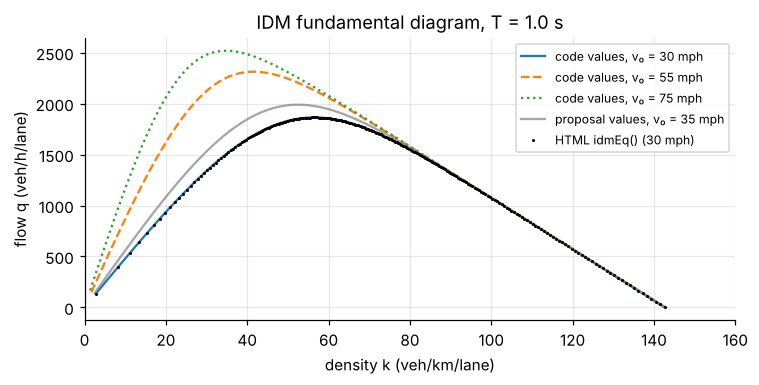

PASS: T2a HTML q–k curve = equation — 1,865 vs 1,865 veh/h/lane (0.00%)
PASS: T2b proposal capacity table reproduced — max difference 0.26%
FLAG: T2c capacity at code values — 1,865 veh/h/lane at the code's 30 mph mean, below the proposal's 35–75 mph range (1,990–2,520)


In [4]:
# 1. code curve vs python (code units: veh/mi, veh/h, mph mean v0 = 30)
eq = np.array(probe["idm_eq"]); cap_js = eq[:,1].max()
cap_py, k_py = th.idm_capacity(30*MPH, 1.0, 8*FT, 15*FT)
d1 = abs(cap_js - cap_py) / cap_py
print(f"HTML idmEq peak {cap_js:,.0f} veh/h/lane vs Python {cap_py:,.0f} veh/h/lane at k = {k_py:.1f} veh/km")

# 2. proposal table
prop = {35: (1990, 1520), 55: (2320, 1720), 75: (2520, 1840)}
rows = []
for vl, (c1, c15) in prop.items():
    for T, cp in ((1.0, c1), (1.5, c15)):
        c = th.idm_capacity(vl*MPH, T, 2.0, 5.0)[0]
        rows.append(dict(speed_limit_mph=vl, T_s=T, proposal_vph=cp, recomputed_vph=round(c), diff_pct=100*(c-cp)/cp))
t2 = pd.DataFrame(rows); display(t2)
d2 = t2.diff_pct.abs().max()

# 3. code values
rows = [dict(v0_mph=vm, T_s=T, cap_code_params=round(th.idm_capacity(vm*MPH, T, 8*FT, 15*FT)[0]),
             cap_proposal_params=round(th.idm_capacity(vm*MPH, T, 2.0, 5.0)[0])) for vm in (30, 35, 55, 75) for T in (1.0, 1.5)]
t2b = pd.DataFrame(rows); display(t2b)

fig, ax = plt.subplots(figsize=(7, 3.6))
for vm, ls in ((30, "-"), (55, "--"), (75, ":")):
    _, k, q = th.idm_equilibrium(vm*MPH, 1.0, 8*FT, 15*FT); ax.plot(k, q, ls, label=f"code values, v₀ = {vm} mph")
_, k, q = th.idm_equilibrium(35*MPH, 1.0, 2.0, 5.0); ax.plot(k, q, color="gray", alpha=.7, label="proposal values, v₀ = 35 mph")
ax.plot(eq[:,0]/KMH, eq[:,1], "k.", ms=2, label="HTML idmEq() (30 mph)")
ax.set(xlabel="density k (veh/km/lane)", ylabel="flow q (veh/h/lane)", title="IDM fundamental diagram, T = 1.0 s", xlim=(0, 160)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

record("T2a HTML q–k curve = equation", "PASS" if d1 < 0.005 else "FLAG", f"{cap_js:,.0f} vs {cap_py:,.0f} veh/h/lane ({100*d1:.2f}%)")
record("T2b proposal capacity table reproduced", "PASS" if d2 < 1 else "FLAG", f"max difference {d2:.2f}%")
record("T2c capacity at code values", "FLAG", f"{cap_py:,.0f} veh/h/lane at the code's 30 mph mean, below the proposal's 35–75 mph range (1,990–2,520)")

## Test 3: QA/QC on every run (proposal 2.3)

The proposal's QA/QC script checks, on every run: **conservation** (vehicles in = out + on the road + unmet demand), **no negative gaps** (no overlapping cars), and correct lane order. The runner checks gaps after every 0.1 s step. We run five scenarios that stress different parts of the code.

In [5]:
scen = {
    "default sliders":            dict(),
    "light, no ramp":             dict(flow=800, ramp=0, crash=0),
    "congested merge":            dict(flow=2800, ramp=700, meter=4.5, crash=0),
    "ramp spillback (n_max)":     dict(flow=3200, ramp=1200, meter=5, crash=0),
    "frequent crashes":           dict(flow=2400, ramp=400, crash=300, clear=0.1),
    "lane changes off":           dict(flow=2400, ramp=600, lc=False, crash=0),
}
outs3 = st.run_many([dict(params=p, duration_s=3600, seed=1) for p in scen.values()])
t3 = pd.DataFrame([dict(scenario=k, **o["checks"], crashes=o["summary"]["crashes"], turned_away=o["summary"]["ramp_turned_away"],
                        exited=o["summary"]["exited"], runtime_s=o["runtime_ms"]/1000) for k, o in zip(scen, outs3)])
display(t3)
ok = (t3.negative_gap_events.eq(0) & t3.order_errors.eq(0) & t3.main_balance.eq(0) & t3.ramp_balance.eq(0)).all()
record("T3 conservation, no negative gaps, lane order", "PASS" if ok else "FLAG",
       f"{len(t3)} scenarios × 36,000 steps; min gap {t3.min_gap_ft.min():.2f} ft")

,scenario,negative_gap_events,min_gap_ft,order_errors,main_balance,ramp_balance,crashes,turned_away,exited,runtime_s
0,default sliders,0,4.504,0,0,0,0,0,1989,4.332
1,"light, no ramp",0,7.188,0,0,0,0,0,704,0.847
2,congested merge,0,3.895,0,0,0,0,27,2643,8.449
3,ramp spillback (n_max),0,5.269,0,0,0,0,483,2634,9.098
4,frequent crashes,0,4.889,0,0,0,0,0,2403,5.081
5,lane changes off,0,5.062,0,0,0,0,0,2189,3.038


PASS: T3 conservation, no negative gaps, lane order — 6 scenarios × 36,000 steps; min gap 3.89 ft


## Test 4: free flow and detector consistency

Light traffic (800 veh/h on the main road, no ramp, no crashes). Expected:
- Detector flows at A and D equal the input demand within Poisson noise (±3√N).
- At every interval, time-mean speed ≥ space-mean speed (Lecture 02).
- Mean speed close to the mean desired speed (30 mph). Some loss is expected because fast drivers sit behind slow ones until they can pass.

In [6]:
outs4 = st.run_many([dict(params=dict(flow=800, ramp=0, crash=0), duration_s=3600, seed=s) for s in (1, 2)])
rows = []
for o in outs4:
    d = st.detectors_df(o); d = d[d.t0 >= 600]
    for sen in "AD":
        x = d[d.sensor == sen]; N = x["count"].sum(); hrs = (3600 - 600) / 3600
        rows.append(dict(seed=o["seed"], sensor=sen, count=N, expected=800*hrs, z=(N-800*hrs)/np.sqrt(800*hrs),
                         time_mean_mph=np.average(x.tmean_mph.dropna(), weights=x.loc[x.tmean_mph.notna(),"count"]),
                         space_mean_mph=np.average(x.smean_mph.dropna(), weights=x.loc[x.smean_mph.notna(),"count"]),
                         ut_ge_us=bool((x.dropna(subset=["tmean_mph","smean_mph"]).eval("tmean_mph >= smean_mph - 1e-9")).all())))
t4 = pd.DataFrame(rows); display(t4)
record("T4a detector flow = input demand", "PASS" if (t4.z.abs() < 3).all() else "FLAG", f"|z| ≤ {t4.z.abs().max():.2f}")
record("T4b time-mean ≥ space-mean speed", "PASS" if t4.ut_ge_us.all() else "FLAG", "every 30 s interval at A and D")
record("T4c free-flow speed", "INFO", f"space-mean {t4.space_mean_mph.mean():.1f} mph vs mean desired 30 mph "
       f"({100*(1-t4.space_mean_mph.mean()/30):.0f}% lower: platoons behind slower drivers)")

,seed,sensor,count,expected,z,time_mean_mph,space_mean_mph,ut_ge_us
0,1,A,630,666.667,-1.420,28.304,28.014,True
1,1,D,641,666.667,-0.994,28.157,27.819,True
2,2,A,634,666.667,-1.265,28.027,27.719,True
3,2,D,621,666.667,-1.769,28.056,27.773,True


PASS: T4a detector flow = input demand — |z| ≤ 1.77
PASS: T4b time-mean ≥ space-mean speed — every 30 s interval at A and D
INFO: T4c free-flow speed — space-mean 27.8 mph vs mean desired 30 mph (7% lower: platoons behind slower drivers)


## Test 5: ramp queue vs. M/D/1 (proposal 1.1 table)

The meter holds each car at the stop line for a fixed time, so it is a deterministic server with μ = 3600 / (seconds per car). Ramp arrivals are Poisson. We use the three (λ, μ) rows from the proposal's M/D/1 table, with light main-road traffic so merging never limits the meter. 2-hour runs, 3 seeds each.

Detector C reports the time-average number of cars in storage, **including the car at the stop line**, so it should match $L = L_q + \rho$, not $L_q = \bar Q$ alone.

,lam_vph,mu_vph,rho,Lq_proposal,L_theory,L_sim,wait_theory_s,wait_sim_s,L_err_pct
0,400,900,0.444,0.178,0.622,0.624,5.6,5.558,0.224
1,600,900,0.667,0.667,1.333,1.408,8.0,8.326,5.627
2,600,720,0.833,2.083,2.917,3.436,17.5,20.372,17.802


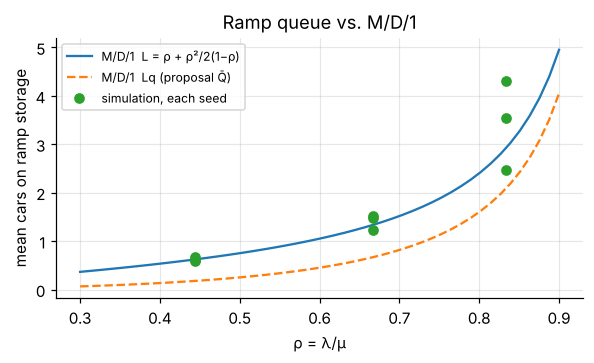

PASS: T5 ramp queue = M/D/1 — mean queue within 18% of L (3 seeds × 2 h each); the gap grows with ρ, likely because the meter also waits for the previous car to move s0 ahead


In [7]:
cases = [(400, 900), (600, 900), (600, 720)]
cfg = [dict(params=dict(flow=800, ramp=lam, meter=3600/mu, crash=0), duration_s=7200, seed=s) for lam, mu in cases for s in (1, 2, 3)]
outs5 = st.run_many(cfg)
rows = []
for o in outs5:
    d = st.detectors_df(o); c = d[(d.sensor == "C") & (d.t0 >= 600)]
    lam, mu = o["params"]["ramp"], 3600 / o["params"]["meter"]; m = th.md1(lam, mu)
    rows.append(dict(lam_vph=lam, mu_vph=round(mu), rho=m["rho"], Lq_proposal=m["Lq"], L_theory=m["L"], L_sim=c.avg_queue.mean(),
                     wait_theory_s=(m["Lq"]/lam*3600 + 3600/mu), wait_sim_s=np.average(c.avg_wait_s.dropna(), weights=c.loc[c.avg_wait_s.notna(), "count"])))
t5 = pd.DataFrame(rows).groupby(["lam_vph","mu_vph"], sort=False).mean().reset_index()
t5["L_err_pct"] = 100 * (t5.L_sim - t5.L_theory) / t5.L_theory
display(t5)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
r = np.linspace(0.3, 0.9, 50); ax.plot(r, r + r**2/(2*(1-r)), label="M/D/1  L = ρ + ρ²/2(1−ρ)"); ax.plot(r, r**2/(2*(1-r)), "--", label="M/D/1  Lq (proposal Q̄)")
ax.plot(pd.DataFrame(rows).rho, pd.DataFrame(rows).L_sim, "o", label="simulation, each seed")
ax.set(xlabel="ρ = λ/μ", ylabel="mean cars on ramp storage", title="Ramp queue vs. M/D/1"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
worst = t5.L_err_pct.abs().max()
record("T5 ramp queue = M/D/1", "PASS" if worst < 20 else "FLAG", f"mean queue within {worst:.0f}% of L (3 seeds × 2 h each); the gap grows with ρ, "
       "likely because the meter also waits for the previous car to move s0 ahead")

## Test 6: breakdown threshold at the merge (proposal 2.1 prediction)

The proposal predicts breakdown once the right lane's load passes lane capacity: $q_{A,right} + q_B > C_{lane}$, so $q_B^* = C_{lane} - q_A/2$. With q_A = 2,400 veh/h:
- at the code's values (v₀ = 30 mph): $q_B^* = 1{,}865 - 1{,}200 \approx 665$ veh/h
- in the proposal (35 mph, T = 1 s): ≈ 790 veh/h

We sweep q_B = 300–1,200 veh/h with the meter at 2 s/car (1,800 veh/h, fast enough not to limit the ramp), 3 seeds each.

Two ways to spot the threshold:
- **Merge capacity reached:** flow at D falls more than 5% below demand q_A + q_B. This is the direct test of the prediction.
- **The code's breakdown rule:** right-lane speed at detector A below 60% of the mean desired speed for 1.5 min. A sits 1 km upstream of the merge, so it only fires when the queue reaches back that far.

,flow_D_vph,unserved_pct,trip_speed_mph,right_lane_speed_A_mph,breakdowns,minutes_broken_down,ramp_wait_s
qB,,,,,,,
300,2686.0,0.5,21.3,22.7,0.7,1.3,57.7
450,2815.6,1.2,20.7,22.7,1.0,1.0,71.6
600,2854.4,4.9,19.1,22.5,1.0,1.5,96.7
750,2912.4,7.5,17.0,22.3,2.0,2.3,311.9
900,2904.0,12.0,16.9,22.2,2.3,3.5,376.3
1200,2910.0,19.2,16.1,21.8,2.3,3.5,435.0


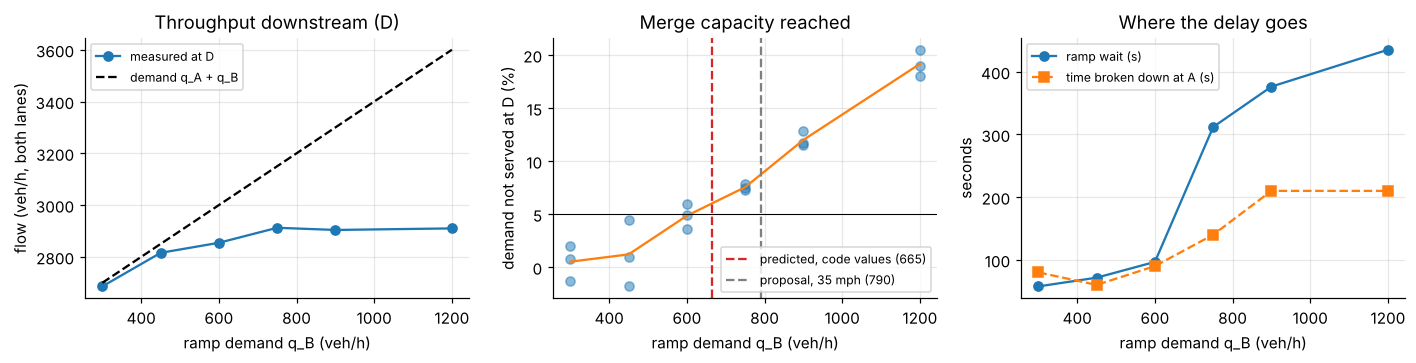

PASS: T6 merge capacity threshold — unserved demand passes 5% between 600 and 750 veh/h ramp demand vs predicted 665 (code values); D flow levels off near 2,912 veh/h
INFO: T6b detector-A breakdown rule — right-lane speed at A stays 22–23 mph, above the 18 mph trigger; the delay shows up as ramp wait (58 → 435 s) because the merge gives the main road priority


In [8]:
qBs = [300, 450, 600, 750, 900, 1200]
outs6 = st.run_many([dict(params=dict(flow=2400, ramp=qb, meter=2.0, crash=0), duration_s=3600, seed=s) for qb in qBs for s in (1, 2, 3)])
rows = []
for o in outs6:
    r = st.summary_row(o, qB=o["params"]["ramp"])
    bd = o["breakdowns"]
    r["minutes_broken_down"] = sum(((b["end_s"] or o["duration_s"]) - b["start_s"]) for b in bd) / 60
    r["first_breakdown_min"] = bd[0]["start_s"] / 60 if bd else np.nan
    d = st.detectors_df(o); a = d[(d.sensor == "A") & (d.lane == "R") & (d.t0 >= 600)]
    r["right_lane_speed_A_mph"] = a.smean_mph.mean()
    rows.append(r)
t6 = pd.DataFrame(rows)
t6["unserved_pct"] = 100 * (1 - t6.flow_D_vph / (2400 + t6.qB))
g6 = t6.groupby("qB")[["flow_D_vph","unserved_pct","trip_speed_mph","right_lane_speed_A_mph","breakdowns","minutes_broken_down","ramp_wait_s"]].mean()
display(g6.round(1))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(g6.index, g6.flow_D_vph, "o-", label="measured at D"); ax[0].plot(g6.index, 2400 + g6.index, "k--", label="demand q_A + q_B")
ax[0].set(xlabel="ramp demand q_B (veh/h)", ylabel="flow (veh/h, both lanes)", title="Throughput downstream (D)"); ax[0].legend(fontsize=8)
ax[1].plot(t6.qB, t6.unserved_pct, "o", alpha=.5); ax[1].plot(g6.index, g6.unserved_pct, "-"); ax[1].axhline(5, color="k", lw=.7)
for x, c, l in ((665, "C3", "predicted, code values (665)"), (790, "gray", "proposal, 35 mph (790)")): ax[1].axvline(x, color=c, ls="--", label=l)
ax[1].set(xlabel="ramp demand q_B (veh/h)", ylabel="demand not served at D (%)", title="Merge capacity reached"); ax[1].legend(fontsize=8)
ax[2].plot(g6.index, g6.ramp_wait_s, "o-", label="ramp wait (s)"); ax[2].plot(g6.index, g6.minutes_broken_down*60, "s--", label="time broken down at A (s)")
ax[2].set(xlabel="ramp demand q_B (veh/h)", ylabel="seconds", title="Where the delay goes"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "breakdown_sweep.png", dpi=150); plt.show()
over = g6.index[g6.unserved_pct > 5]
lo = [q for q in g6.index if q < (over[0] if len(over) else 1e9)]
obs = f"between {lo[-1]} and {over[0]}" if len(over) and lo else "not reached"
ok = len(over) and lo and lo[-1] <= 665 <= over[0] + 150
record("T6 merge capacity threshold", "PASS" if ok else "FLAG",
       f"unserved demand passes 5% {obs} veh/h ramp demand vs predicted 665 (code values); D flow levels off near {g6.flow_D_vph.max():,.0f} veh/h")
record("T6b detector-A breakdown rule", "INFO",
       f"right-lane speed at A stays {g6.right_lane_speed_A_mph.min():.0f}–{g6.right_lane_speed_A_mph.max():.0f} mph, above the 18 mph trigger; "
       f"the delay shows up as ramp wait ({g6.ramp_wait_s.iloc[0]:.0f} → {g6.ramp_wait_s.iloc[-1]:.0f} s) because the merge gives the main road priority")

## Test 7: wave speed, x–t and q–k diagrams

Congested scenario from the parameter doc: q_A = 2,800 veh/h, q_B = 700 veh/h, meter 4.5 s/car. The HTML measures wave speed by cross-correlating congested speeds 800 ft apart in its x–t speed field. Expected (Lecture 04, slide 24): −20 to −15 km/h. Newell's $w = -(l + s_0)/T$ gives −25 km/h at the code's l and s₀, and −18 km/h with the proposal's l_eff = 5 m.

measured wave speed (km/h): [-18.3 -18.3 -18.3] | Newell, code l+s0: -25.2 | Newell, proposal l_eff = 5 m: -18.0


,seed,start_s,end_s,breakdown_flow_vph,discharge_flow_vph,capacity_drop_pct,shockwave_mph,crash
0,1,840,NaN,3330.0,2923.5,12.2,3.6,False
1,2,1230,3120.0,2892.0,2936.1,-1.5,NaN,False
2,2,3210,NaN,NaN,2940.0,NaN,NaN,False
3,3,1170,NaN,2856.0,2932.5,-2.7,-5.1,False


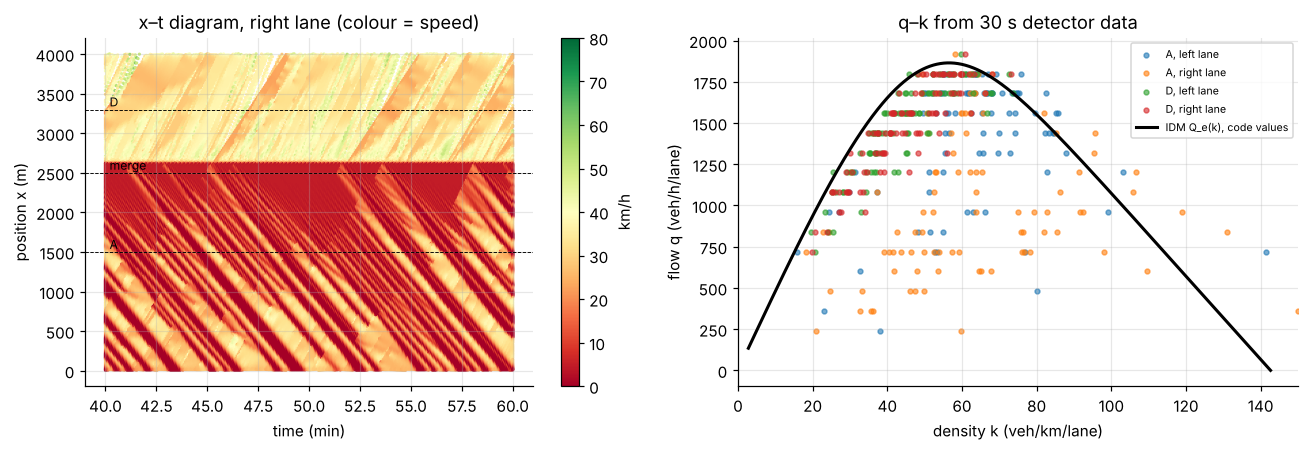

PASS: T7a measured wave speed in lecture range — [-18.3, -18.3, -18.3] km/h vs −20 to −15 km/h
FLAG: T7b Newell check at code values — Newell −(l+s0)/T = -25.2 km/h at code l, s0; -18.0 km/h with proposal l_eff = 5 m


In [9]:
outs7 = st.run_many([dict(params=dict(flow=2800, ramp=700, meter=4.5, crash=0), duration_s=3600, seed=s,
                          record_traj=(s == 1), traj_every_s=4, traj_from_s=2400) for s in (1, 2, 3)])
w = [o["wave_xcorr_mph"]["right"] for o in outs7 if o["wave_xcorr_mph"]["right"] is not None]
w_kmh = np.array(w) * KMH
newell_code = th.newell_wave_speed_kmh(15*FT + 8*FT, 1.0); newell_prop = th.newell_wave_speed_kmh(5.0, 1.0)
print("measured wave speed (km/h):", np.round(w_kmh, 1), "| Newell, code l+s0:", round(newell_code, 1), "| Newell, proposal l_eff = 5 m:", round(newell_prop, 1))
bd7 = pd.DataFrame([dict(seed=o["seed"], **b) for o in outs7 for b in o["breakdowns"]])
display(bd7.round(1))

o = outs7[0]; tj = st.traj_df(o); tr = tj[tj.lane == 0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sc = ax[0].scatter(tr.t_s/60, tr.x_m, c=tr.v_kmh, s=1.2, cmap="RdYlGn", vmin=0, vmax=80)
for x, nm in ((1500, "A"), (2500, "merge"), (3300, "D")): ax[0].axhline(x, color="k", lw=.6, ls="--"); ax[0].text(40.2, x+40, nm, fontsize=8)
ax[0].set(xlabel="time (min)", ylabel="position x (m)", title="x–t diagram, right lane (colour = speed)"); plt.colorbar(sc, ax=ax[0], label="km/h")
d = st.detectors_df(o); d = d[d.sensor.isin(["A", "D"]) & (d.t0 >= 600)]
for (sen, ln), g in d.groupby(["sensor", "lane"]):
    ax[1].scatter(g.density_vpkm, g.flow_vph, s=10, alpha=.6, label=f"{sen}, {'right' if ln=='R' else 'left'} lane")
_, k, q = th.idm_equilibrium(30*MPH, 1.0, 8*FT, 15*FT); ax[1].plot(k, q, "k-", lw=2, label="IDM Q_e(k), code values")
ax[1].set(xlabel="density k (veh/km/lane)", ylabel="flow q (veh/h/lane)", title="q–k from 30 s detector data", xlim=(0, 150)); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "xt_qk_congested.png", dpi=150); plt.show()
inside = bool(len(w_kmh)) and np.all((w_kmh >= -20) & (w_kmh <= -15))
record("T7a measured wave speed in lecture range", "PASS" if inside else "FLAG", f"{np.round(w_kmh,1).tolist()} km/h vs −20 to −15 km/h")
record("T7b Newell check at code values", "FLAG" if not (-20 <= newell_code <= -15) else "PASS",
       f"Newell −(l+s0)/T = {newell_code:.1f} km/h at code l, s0; {newell_prop:.1f} km/h with proposal l_eff = 5 m")

## Test 8: braking pulse and string stability (proposal 2.2 disturbance)

A car in the right lane near x = 1,800 m brakes at −3 m/s² for 3 s, 15 min into the run. To isolate the pulse, each case is run twice with the same seed, once with and once without the pulse; the speed difference between the two runs is caused only by the pulse. Lane changes are off so the followers stay behind the braking car.

**Amplification ratio** = largest speed loss of the 10th follower ÷ that of the braking car. Below 1, the disturbance fades (string stable); above 1, it grows. The proposal predicted fading below about 0.8 C and growth between 0.8 C and C.

We compare the code's IDM values (a = 1.52, b = 2.74 m/s²) with the proposal's (a = 1.0, b = 1.5 m/s², s₀ = 2 m, l = 5 m).

median   min   max
params          flow_vph                    
code values     1200        0.80  0.59  0.85
                2400        0.65  0.53  0.93
                3200        0.87  0.76  0.89
proposal values 1200        0.04  0.00  0.12
                2400        0.87  0.84  0.92
                3200        0.87  0.87  0.90

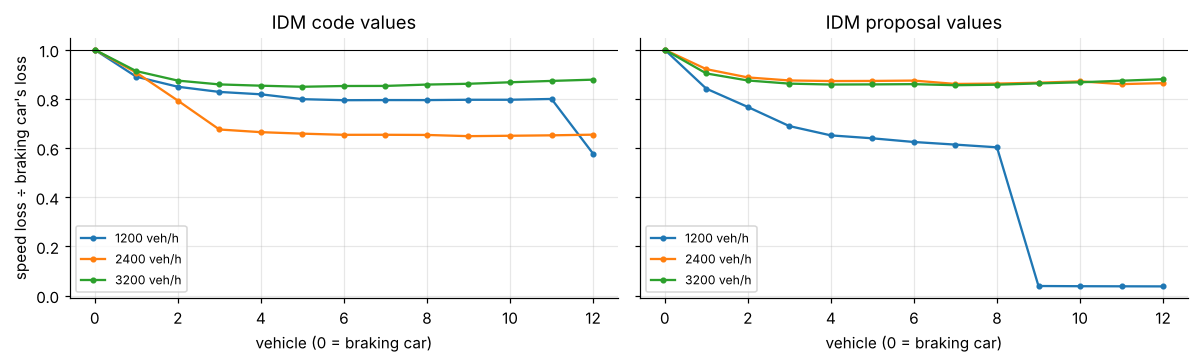

INFO: T8 string stability, code values — median ratio by flow: 1200: 0.80, 2400: 0.65, 3200: 0.87 (all below 1: the pulse fades; the proposal predicted growth near capacity)
INFO: T8 string stability, proposal values — median ratio by flow: 1200: 0.04, 2400: 0.87, 3200: 0.87 (all below 1: the pulse fades; the proposal predicted growth near capacity)


In [10]:
PROPOSAL_CONSTS = dict(IA=1.0/FT, IB=1.5/FT, S0=2.0/FT, CL=5.0/FT)    # proposal car values, converted to ft
pulse = dict(t_s=900, x_m=1800, decel_mps2=3, dur_s=3, lane=0, n_followers=12, window_s=150)
cfg = []
for name, consts in (("code values", {}), ("proposal values", PROPOSAL_CONSTS)):
    for flow in (1200, 2400, 3200):
        for s in (1, 2, 3):
            base = dict(params=dict(flow=flow, ramp=0, crash=0, lc=False), consts=consts, duration_s=1080, seed=s)
            cfg += [dict(base, pulse=dict(pulse, apply=True)), dict(base, pulse=dict(pulse, apply=False))]
outs8 = st.run_many(cfg)
rows, curves = [], {}
for i in range(0, len(outs8), 2):
    a, b = outs8[i], outs8[i+1]
    name = "proposal values" if a["input"]["consts"] else "code values"
    loss = np.nanmax(np.array(b["pulse"]["v_mph"], float) - np.array(a["pulse"]["v_mph"], float), axis=0) * KMH
    rows.append(dict(params=name, flow_vph=a["params"]["flow"], seed=a["seed"], lead_loss_kmh=loss[0], f10_loss_kmh=loss[10], ratio=loss[10]/loss[0]))
    curves.setdefault((name, a["params"]["flow"]), []).append(loss / loss[0])
t8 = pd.DataFrame(rows)
g8 = t8.groupby(["params", "flow_vph"]).ratio.agg(["median", "min", "max"]); display(g8.round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for j, name in enumerate(("code values", "proposal values")):
    for flow in (1200, 2400, 3200):
        ax[j].plot(np.median(curves[(name, flow)], axis=0), "o-", ms=3, label=f"{flow} veh/h")
    ax[j].axhline(1, color="k", lw=.7); ax[j].set(title=f"IDM {name}", xlabel="vehicle (0 = braking car)"); ax[j].legend(fontsize=8)
ax[0].set_ylabel("speed loss ÷ braking car's loss"); plt.tight_layout(); plt.show()
for name in ("code values", "proposal values"):
    m = g8.loc[name, "median"]
    record(f"T8 string stability, {name}", "INFO", "median ratio by flow: " + ", ".join(f"{f}: {r:.2f}" for f, r in m.items())
           + (" (all below 1: the pulse fades; the proposal predicted growth near capacity)" if m.max() < 1 else " (some above 1: the pulse grows at these flows)"))

## Test 9: time-step convergence (proposal 2.3)

Rerun with Δt = 0.05 s and compare against Δt = 0.1 s. The runner rewrites the HTML's step-count timers as times, so detector intervals stay 30 s. Arrivals differ between the two time steps, so we compare means over 3 seeds. Pass if mean trip time, flow at D and ramp wait change by less than 5%, or by less than two standard errors of the seed-to-seed spread (in which case the difference is noise, not a time-step effect).

In [11]:
sc9 = {"default sliders": dict(), "congested merge": dict(flow=2800, ramp=700, meter=4.5, crash=0)}
cfg = [dict(params=p, consts=({"DT": dt} if dt != 0.1 else {}), duration_s=3600, seed=s) for p in sc9.values() for dt in (0.1, 0.05) for s in (1, 2, 3)]
outs9 = st.run_many(cfg)
rows = [st.summary_row(o, scenario=k, dt=o["consts"]["DT"]) for o, k in zip(outs9, [k for k in sc9 for _ in range(6)])]
r9 = pd.DataFrame(rows)
t9 = r9.groupby(["scenario", "dt"])[["mean_trip_s", "flow_D_vph", "ramp_wait_s", "neg_gaps"]].mean()
display(t9.round(1))
rel = []
for k in sc9:
    for c in ("mean_trip_s", "flow_D_vph", "ramp_wait_s"):
        a = r9[(r9.scenario == k) & (r9.dt == 0.1)][c]; b = r9[(r9.scenario == k) & (r9.dt == 0.05)][c]
        se = np.sqrt(a.var()/len(a) + b.var()/len(b))
        rel.append(dict(scenario=k, measure=c, change_pct=100*(b.mean()-a.mean())/a.mean(), diff_over_2se=abs(b.mean()-a.mean())/(2*se)))
rel = pd.DataFrame(rel); rel["ok"] = (rel.change_pct.abs() < 5) | (rel.diff_over_2se < 1); display(rel.round(2))
worst = rel.loc[rel.change_pct.abs().idxmax()]
record("T9 Δt = 0.1 vs 0.05 s", "PASS" if rel.ok.all() else "FLAG",
       f"largest change {worst.change_pct:+.1f}% ({worst.measure}, {worst.scenario}; {'within' if worst.diff_over_2se < 1 else 'outside'} seed noise); others ≤ "
       f"{rel.drop(worst.name).change_pct.abs().max():.1f}%")

mean_trip_s  flow_D_vph  ramp_wait_s  neg_gaps
scenario        dt                                                  
congested merge 0.05        611.7      2905.2        357.2       0.0
                0.10        621.4      2935.6        318.3       0.0
default sliders 0.05        378.2      2174.0         54.8       0.0
                0.10        373.0      2200.8         54.9       0.0

,scenario,measure,change_pct,diff_over_2se,ok
0,default sliders,mean_trip_s,1.39,0.62,True
1,default sliders,flow_D_vph,-1.22,0.47,True
2,default sliders,ramp_wait_s,-0.09,0.04,True
3,congested merge,mean_trip_s,-1.56,0.29,True
4,congested merge,flow_D_vph,-1.04,1.06,True
5,congested merge,ramp_wait_s,12.23,0.97,True


PASS: T9 Δt = 0.1 vs 0.05 s — largest change +12.2% (ramp_wait_s, congested merge; within seed noise); others ≤ 1.6%


## Test 10: what changes if we switch to the proposal's IDM values?

The parameter table shows the code's a, b, s₀ and l differ from the proposal. Same congested scenario as Test 7, 3 seeds, with the code's values vs. the proposal's car values (mean desired speed stays 30 mph so only the IDM constants change). This informs the "Decisions to make" list.

In [12]:
cfg = [dict(params=dict(flow=2800, ramp=700, meter=4.5, crash=0), consts=c, duration_s=3600, seed=s)
       for c in ({}, PROPOSAL_CONSTS) for s in (1, 2, 3)]
outs10 = st.run_many(cfg)
rows = []
for o in outs10:
    r = st.summary_row(o, params=("proposal values" if o["input"]["consts"] else "code values"))
    bd = o["breakdowns"]; r["breakdown_flow_vph"] = np.nanmean([b["breakdown_flow_vph"] or np.nan for b in bd]) if bd else np.nan
    r["discharge_flow_vph"] = np.nanmean([b["discharge_flow_vph"] or np.nan for b in bd]) if bd else np.nan
    rows.append(r)
t10 = pd.DataFrame(rows).groupby("params")[["flow_D_vph","trip_speed_mph","ramp_wait_s","ramp_turned_away","breakdowns","breakdown_flow_vph","discharge_flow_vph","wave_right_mph"]].mean()
t10["wave_right_kmh"] = t10.wave_right_mph * KMH
t10["capacity_theory_vph_lane"] = [th.idm_capacity(30*MPH, 1.0, 8*FT, 15*FT)[0], th.idm_capacity(30*MPH, 1.0, 2.0, 5.0)[0]]
display(t10.round(1))
dq = 100 * (t10.loc["proposal values", "flow_D_vph"] / t10.loc["code values", "flow_D_vph"] - 1)
record("T10 proposal vs code IDM values", "INFO", f"throughput at D changes {dq:+.1f}% with the proposal's a, b, s0, l")

,flow_D_vph,trip_speed_mph,ramp_wait_s,ramp_turned_away,breakdowns,breakdown_flow_vph,discharge_flow_vph,wave_right_mph,wave_right_kmh,capacity_theory_vph_lane
params,,,,,,,,,,
code values,2935.6,12.9,318.3,43.7,1.3,3026.0,2931.4,-11.4,-18.3,1864.7
proposal values,2715.2,12.4,377.4,83.7,4.7,2731.1,2694.0,-10.2,-16.5,1871.9


INFO: T10 proposal vs code IDM values — throughput at D changes -7.5% with the proposal's a, b, s0, l


## Summary

In [13]:
summary = pd.DataFrame(RESULTS)
summary.to_csv(OUT / "test_summary.csv", index=False)
with pd.option_context("display.max_colwidth", 160):
    display(summary)
print(summary.result.value_counts().to_string())
print(f"Total runtime {time.time() - T0:.0f} s. Results saved in {OUT.relative_to(REPO)}/")

,test,result,detail
0,Parameters vs. proposal,FLAG,"7 differ or fall outside the cited range: v0, a, b, l, q_A, q_B, μ"
1,T1 idm() = lecture IDM equation,PASS,max error 1.8e-12 ft/s²
2,T2a HTML q–k curve = equation,PASS,"1,865 vs 1,865 veh/h/lane (0.00%)"
3,T2b proposal capacity table reproduced,PASS,max difference 0.26%
4,T2c capacity at code values,FLAG,"1,865 veh/h/lane at the code's 30 mph mean, below the proposal's 35–75 mph range (1,990–2,520)"
5,"T3 conservation, no negative gaps, lane order",PASS,"6 scenarios × 36,000 steps; min gap 3.89 ft"
6,T4a detector flow = input demand,PASS,|z| ≤ 1.77
7,T4b time-mean ≥ space-mean speed,PASS,every 30 s interval at A and D
8,T4c free-flow speed,INFO,space-mean 27.8 mph vs mean desired 30 mph (7% lower: platoons behind slower drivers)
9,T5 ramp queue = M/D/1,PASS,"mean queue within 18% of L (3 seeds × 2 h each); the gap grows with ρ, likely because the meter also waits for the previous car to move s0 ahead"


result
PASS    10
INFO     5
FLAG     3
Total runtime 209 s. Results saved in stage3_two_lane_merge/results/


## Adding your own test

Copy this pattern. Any slider in the HTML can be set through `params` (names in `simtools.bridge.SLIDERS`); hard-coded constants through `consts` (`simtools.bridge.CONSTS`).

```python
out = st.run_stage3(params=dict(flow=2400, ramp=900, meter=4.0), consts=dict(DT=0.1), duration_s=3600, seed=7)
det = st.detectors_df(out)          # 30 s records for detectors A, B, C, D
out["summary"], out["checks"], out["breakdowns"], out["wave_xcorr_mph"]
```

Ideas not built yet, from the proposal: TTC < 3 s conflict counts (needs a TTC log in the HTML), Power Model severity by speed limit, the crash-blockage D/D/1 check, the K-factor demand input, and the Newell model for the CEE 281 comparison.